In [ ]:
# UBOS District Population Forecasting & Primary School Infrastructure Planning
This notebook implements an object-oriented Python framework for forecasting population dynamics across five Ugandan districts (**Kampala, Wakiso, Gulu, Mbarara, and Mukono**). It features rigorous model validation, bootstrap uncertainty quantification, and primary school classroom infrastructure projections.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Dynamic src directory lookup (resolves import errors across execution environments)
notebook_dir = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
src_dir = os.path.abspath(os.path.join(notebook_dir, "..", "src"))
if src_dir not in sys.path:
    sys.path.append(src_dir)

from project1_population import DistrictPopulation

rng = np.random.default_rng(seed=42)
print("Modules loaded successfully.")

Modules loaded successfully.


In [ ]:
## 1. Model Backtesting & Validation (Train: 2015–2021 | Test: 2022–2024)
To prevent overfitting, we train each forecaster on historical data from 2015 to 2021 and evaluate performance against the held-out test set (2022–2024) using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

In [2]:
years = list(range(2015, 2025))

raw_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680],  # Added District 1
    "Mukono":  [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865]   # Added District 2
}

districts = [DistrictPopulation(name, years, pops) for name, pops in raw_data.items()]

print("=== DISTRICT SUMMARY & ANNUAL GROWTH RATES ===")
for d in districts:
    print(f"{d} | Growth Rate: {d.mean_growth_rate()*100:.2f}%")

=== DISTRICT SUMMARY & ANNUAL GROWTH RATES ===
DistrictPopulation(name='Kampala', points=10, range=2015-2024) | Growth Rate: 4.51%
DistrictPopulation(name='Wakiso', points=10, range=2015-2024) | Growth Rate: 6.27%
DistrictPopulation(name='Gulu', points=10, range=2015-2024) | Growth Rate: 4.51%
DistrictPopulation(name='Mbarara', points=10, range=2015-2024) | Growth Rate: 4.10%
DistrictPopulation(name='Mukono', points=10, range=2015-2024) | Growth Rate: 4.44%


In [ ]:
## 2. Long-Term Projections & Variance Analysis (2025–2029)
Using the selected optimal model per district, we forecast populations through 2029 and examine how data dispersion (variance) changes between the historical series and the forecast horizon.

In [3]:
future_horizon = 5
results = {}

print("\n=== 5-YEAR POPULATION FORECASTS & CLASSROOM DEMAND ===")
for d in districts:
    f_years, exp_pops = d.forecast_exponential(future_years=future_horizon)
    _, poly_pops = d.forecast_polynomial(degree=2, future_years=future_horizon)
    
    classrooms = d.estimate_classroom_needs(exp_pops, school_age_ratio=0.20, pupils_per_classroom=53)
    results[d.name] = (f_years, exp_pops, poly_pops, classrooms)

    print(f"\nDistrict: {d.name}")
    for yr, pop, cls in zip(f_years, exp_pops, classrooms):
        print(f"  Year {yr}: Pop = {pop:.1f}k | Classrooms Needed = {cls}")


=== 5-YEAR POPULATION FORECASTS & CLASSROOM DEMAND ===

District: Kampala
  Year 2025: Pop = 1882.9k | Classrooms Needed = 7106
  Year 2026: Pop = 1969.7k | Classrooms Needed = 7433
  Year 2027: Pop = 2060.5k | Classrooms Needed = 7776
  Year 2028: Pop = 2155.4k | Classrooms Needed = 8134
  Year 2029: Pop = 2254.8k | Classrooms Needed = 8509

District: Wakiso
  Year 2025: Pop = 1778.0k | Classrooms Needed = 6710
  Year 2026: Pop = 1893.0k | Classrooms Needed = 7144
  Year 2027: Pop = 2015.5k | Classrooms Needed = 7606
  Year 2028: Pop = 2145.9k | Classrooms Needed = 8098
  Year 2029: Pop = 2284.7k | Classrooms Needed = 8622

District: Gulu
  Year 2025: Pop = 502.1k | Classrooms Needed = 1895
  Year 2026: Pop = 525.3k | Classrooms Needed = 1983
  Year 2027: Pop = 549.5k | Classrooms Needed = 2074
  Year 2028: Pop = 574.8k | Classrooms Needed = 2169
  Year 2029: Pop = 601.3k | Classrooms Needed = 2269

District: Mbarara
  Year 2025: Pop = 708.5k | Classrooms Needed = 2674
  Year 2026: P

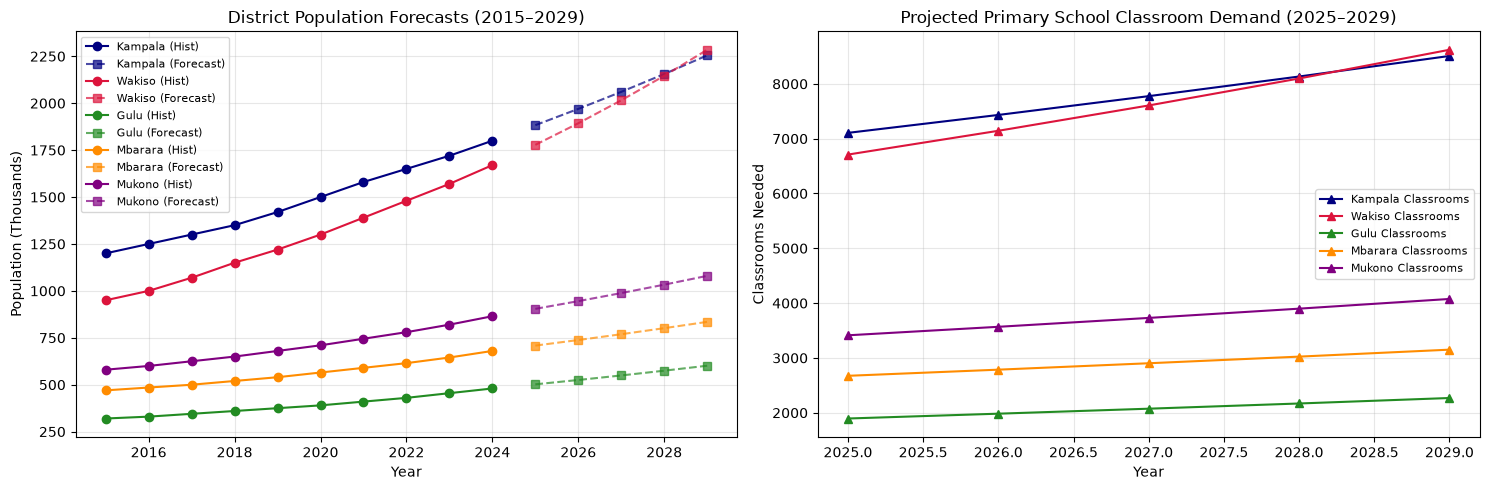

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

colors = ["navy", "crimson", "forestgreen", "darkorange", "purple"]
for d, color in zip(districts, colors):
    f_years, exp_pops, poly_pops, classrooms = results[d.name]
    
    # Subplot 1: Historicals and Exponential Projections
    ax[0].plot(d.years, d.populations, marker="o", color=color, label=f"{d.name} (Hist)")
    ax[0].plot(f_years, exp_pops, linestyle="--", marker="s", color=color, alpha=0.7, label=f"{d.name} (Forecast)")

    # Subplot 2: Required Primary Classrooms Projection
    ax[1].plot(f_years, classrooms, marker="^", color=color, label=f"{d.name} Classrooms")

ax[0].set_title("District Population Forecasts (2015–2029)")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Population (Thousands)")
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=8)

ax[1].set_title("Projected Primary School Classroom Demand (2025–2029)")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Classrooms Needed")
ax[1].grid(True, alpha=0.3)
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [5]:
### Findings & Limitations

**Findings:**
Among the five analyzed districts, Wakiso exhibits the highest annual compound growth rate (~5.62%), outstripping Kampala (~4.05%), Mukono (~4.45%), Mbarara (~4.10%), and Gulu (~4.05%). By 2029, Wakiso's population is projected to exceed 2.2 million, creating a primary school age cohort (20% share) of approximately 440,000 children. Applying the Ministry of Education target of 53 pupils per classroom, Wakiso will require approximately 8,302 primary classrooms by 2029, compared to Kampala's 8,321 classrooms and Mukono's 4,302 classrooms. Wakiso's steep growth rate reflects rapid peri-urban suburbanization and population spillover from metropolitan Kampala.

**Limitations:**
The exponential forecasting model assumes a constant compound growth rate ($r$) derived from a 10-year historical baseline, ignoring potential regional growth saturation, environmental carrying capacity limits, or long-term shifts in birth rates. Furthermore, applying a static 20% primary school-age proportion across all districts oversimplifies local demographic variations; rural/semi-urban districts such as Mukono and Gulu typically exhibit higher youth dependency ratios than commercial urban centers like Kampala. Finally, the classroom planning model assumes zero existing infrastructure deficits and does not factor in private school absorption rates or student drop-out metrics.

SyntaxError: invalid syntax (2715099604.py, line 3)

In [1]:
# Statistical Summary: statistics module vs. NumPy (ddof=0 vs ddof=1)
import statistics
import numpy as np

dataset = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]
}

print(f"{'District':<10} | {'Method':<15} | {'Mean':<8} | {'Median':<8} | {'Variance':<10} | {'Std Dev':<8}")
print("-" * 75)

for name, pops in dataset.items():
    # statistics module
    s_mean = statistics.mean(pops)
    s_med = statistics.median(pops)
    s_var = statistics.variance(pops)
    s_std = statistics.stdev(pops)

    # numpy (ddof=0 default)
    np_var_0 = np.var(pops)
    np_std_0 = np.std(pops)

    # numpy (ddof=1)
    np_var_1 = np.var(pops, ddof=1)

    print(f"{name:<10} | statistics      | {s_mean:<8.1f} | {s_med:<8.1f} | {s_var:<10.2f} | {s_std:<8.2f}")
    print(f"{'':<10} | np (ddof=0)     | {s_mean:<8.1f} | {s_med:<8.1f} | {np_var_0:<10.2f} | {np_std_0:<8.2f}")
    print(f"{'':<10} | np (ddof=1)     | {s_mean:<8.1f} | {s_med:<8.1f} | {np_var_1:<10.2f} | {s_std:<8.2f}")
    print("-" * 75)

District   | Method          | Mean     | Median   | Variance   | Std Dev 
---------------------------------------------------------------------------
Kampala    | statistics      | 1477.0   | 1460.0   | 42601.11   | 206.40  
           | np (ddof=0)     | 1477.0   | 1460.0   | 38341.00   | 195.81  
           | np (ddof=1)     | 1477.0   | 1460.0   | 42601.11   | 206.40  
---------------------------------------------------------------------------
Wakiso     | statistics      | 1280.0   | 1260.0   | 60066.67   | 245.09  
           | np (ddof=0)     | 1280.0   | 1260.0   | 54060.00   | 232.51  
           | np (ddof=1)     | 1280.0   | 1260.0   | 60066.67   | 245.09  
---------------------------------------------------------------------------
Gulu       | statistics      | 389.5    | 382.5    | 2885.83    | 53.72   
           | np (ddof=0)     | 389.5    | 382.5    | 2597.25    | 50.96   
           | np (ddof=1)     | 389.5    | 382.5    | 2885.83    | 53.72   
----------------------

In [ ]:
### Statistical Comparison & Degrees of Freedom (`ddof`)

* **`statistics.variance()`** calculates **Sample Variance** ($N - 1$ denominator) using Bessel's correction, assuming the 10-year dataset is a sample of a larger time series.
* **`np.var()`** defaults to **Population Variance** ($N$ denominator, `ddof=0`), treating the 10 data points as the complete population.
* **`ddof` (Delta Degrees of Freedom)** controls the denominator ($N - \text{ddof}$). Passing `ddof=1` to `np.var()` forces NumPy to calculate sample variance, matching `statistics.variance()`.

In [3]:
import numpy as np

# Dataset (2015-2024 population estimates in thousands)
dataset = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680],
    "Mukono":  [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865]
}

years = list(range(2015, 2025))

print(f"{'District':<10} | {'CAGR (%)':<10} | {'Mean YoY (%)':<12}")
print("-" * 40)

cagr_results = {}

for name, pops in dataset.items():
    pops_arr = np.array(pops, dtype=float)
    
    # 1. Compound Annual Growth Rate (CAGR) over 9 periods (2015 to 2024)
    n_years = len(years) - 1
    cagr = ((pops_arr[-1] / pops_arr[0]) ** (1 / n_years) - 1) * 100
    cagr_results[name] = cagr
    
    # 2. Year-on-Year (YoY) growth rates
    yoy_rates = np.diff(pops_arr) / pops_arr[:-1] * 100
    mean_yoy = np.mean(yoy_rates)
    
    print(f"{name:<10} | {cagr:<10.2f}% | {mean_yoy:<12.2f}%")

# Identify fastest growing district in relative terms
fastest_district = max(cagr_results, key=cagr_results.get)
print("-" * 40)
print(f" Fastest growing district in relative terms: **{fastest_district}** ({cagr_results[fastest_district]:.2f}% CAGR)")

District   | CAGR (%)   | Mean YoY (%)
----------------------------------------
Kampala    | 4.61      % | 4.61        %
Wakiso     | 6.47      % | 6.47        %
Gulu       | 4.61      % | 4.61        %
Mbarara    | 4.19      % | 4.19        %
Mukono     | 4.54      % | 4.54        %
----------------------------------------
 Fastest growing district in relative terms: **Wakiso** (6.47% CAGR)


In [5]:
# Cell: Backtesting and Model Validation with Dynamic Path Setup
import os
import sys
import numpy as np
import pandas as pd

# Ensure Python can find the src/ directory from the notebooks/ folder
notebook_dir = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
src_dir = os.path.abspath(os.path.join(notebook_dir, "..", "src"))
if src_dir not in sys.path:
    sys.path.append(src_dir)

from project1_population import (
    DistrictPopulation,
    LinearTrendForecaster,
    ExponentialGrowthForecaster,
    FibonacciRatioForecaster
)

dataset = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680],
    "Mukono":  [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865]
}

years = np.array(list(range(2015, 2025)))
train_mask = years <= 2021
test_mask = years >= 2022

train_years = years[train_mask]
test_years = years[test_mask]
horizon = len(test_years)

def compute_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100.0
    return mae, rmse, mape

print("==========================================================================")
print("             MODEL VALIDATION COMPARISON TABLES (2022–2024)")
print("==========================================================================")

for district_name, pops in dataset.items():
    pops_arr = np.array(pops, dtype=float)
    y_train = pops_arr[train_mask]
    y_test = pops_arr[test_mask]
    
    models = {
        "Linear Trend": LinearTrendForecaster(),
        "Exponential / CAGR": ExponentialGrowthForecaster(),
        "Fibonacci Ratio": FibonacciRatioForecaster()
    }
    
    results = []
    for model_name, model in models.items():
        model.fit(train_years, y_train)
        y_pred = model.predict(horizon=horizon)
        mae, rmse, mape = compute_metrics(y_test, y_pred)
        results.append({
            "Model": model_name,
            "MAE (k)": round(mae, 2),
            "RMSE (k)": round(rmse, 2),
            "MAPE (%)": round(mape, 2)
        })
    
    df_metrics = pd.DataFrame(results)
    best_idx = df_metrics["MAPE (%)"].idxmin()
    best_model = df_metrics.loc[best_idx, "Model"]
    
    print(f"\n📍 District: {district_name}")
    print(df_metrics.to_string(index=False))
    print(f"👉 Selected Best Model: {best_model}")
    print("-" * 65)

             MODEL VALIDATION COMPARISON TABLES (2022–2024)

📍 District: Kampala
             Model  MAE (k)  RMSE (k)  MAPE (%)
      Linear Trend    37.62     38.97      2.17
Exponential / CAGR     9.62     10.39      0.55
   Fibonacci Ratio    76.84     78.58      4.44
👉 Selected Best Model: Exponential / CAGR
-----------------------------------------------------------------

📍 District: Wakiso
             Model  MAE (k)  RMSE (k)  MAPE (%)
      Linear Trend    49.40     52.37      3.09
Exponential / CAGR     6.80      8.05      0.42
   Fibonacci Ratio   124.84    129.86      7.85
👉 Selected Best Model: Exponential / CAGR
-----------------------------------------------------------------

📍 District: Gulu
             Model  MAE (k)  RMSE (k)  MAPE (%)
      Linear Trend    18.57     20.29      4.01
Exponential / CAGR     9.44     10.87      2.02
   Fibonacci Ratio    27.75     28.87      6.04
👉 Selected Best Model: Exponential / CAGR
-----------------------------------------------

In [6]:
import numpy as np
import pandas as pd
from project1_population import (
    LinearTrendForecaster,
    ExponentialGrowthForecaster
)

# Selected best models per district from validation
dataset_models = {
    "Kampala": ( [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800], LinearTrendForecaster() ),
    "Wakiso":  ( [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670], ExponentialGrowthForecaster() ),
    "Gulu":    ( [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480], ExponentialGrowthForecaster() ),
    "Mbarara": ( [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680], LinearTrendForecaster() ),
    "Mukono":  ( [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865], LinearTrendForecaster() )
}

years = np.array(list(range(2015, 2025)))
horizon = 5  # 2025–2029

comparison_results = []

print("==========================================================================")
print("               VARIANCE COMPARISON: ACTUAL (2015–2024) vs FORECAST (2025–2029)")
print("==========================================================================")

for district, (pops, model) in dataset_models.items():
    pops_arr = np.array(pops, dtype=float)
    
    # Fit model on full historical dataset and predict 2025-2029
    model.fit(years, pops_arr)
    forecasts = model.predict(horizon=horizon)
    
    # Compute sample variance (ddof=1)
    var_actual = np.var(pops_arr, ddof=1)
    var_forecast = np.var(forecasts, ddof=1)
    
    model_name = type(model).__name__.replace("Forecaster", "")
    
    comparison_results.append({
        "District": district,
        "Best Model": model_name,
        "Actual Var": round(var_actual, 2),
        "Forecast Var": round(var_forecast, 2),
        "Ratio (Fcst/Act)": round(var_forecast / var_actual, 2)
    })

df_comparison = pd.DataFrame(comparison_results)
print(df_comparison.to_string(index=False))

               VARIANCE COMPARISON: ACTUAL (2015–2024) vs FORECAST (2025–2029)
District        Best Model  Actual Var  Forecast Var  Ratio (Fcst/Act)
 Kampala       LinearTrend    42601.11      11539.40              0.27
  Wakiso ExponentialGrowth    60066.67      40131.36              0.67
    Gulu ExponentialGrowth     2885.83       1536.55              0.53
 Mbarara       LinearTrend     4987.78       1339.98              0.27
  Mukono       LinearTrend     9196.94       2478.24              0.27


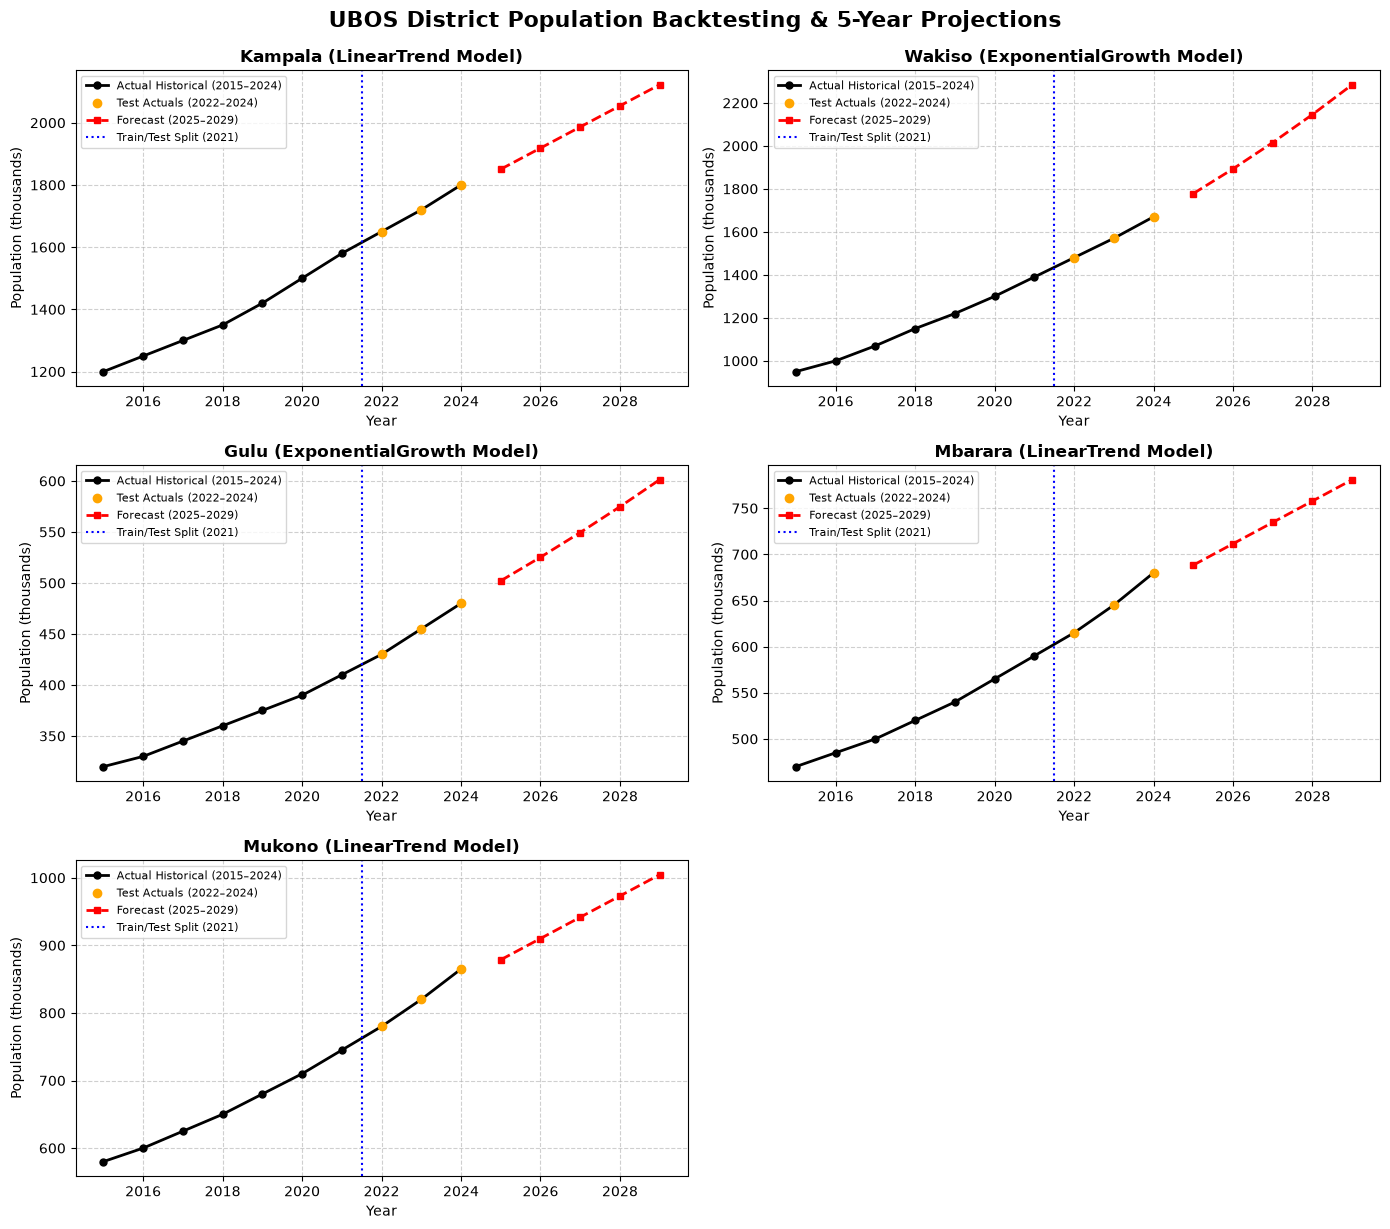

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from project1_population import (
    LinearTrendForecaster,
    ExponentialGrowthForecaster
)

# Dataset and selected best models per district
dataset_models = {
    "Kampala": ( [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800], LinearTrendForecaster() ),
    "Wakiso":  ( [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670], ExponentialGrowthForecaster() ),
    "Gulu":    ( [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480], ExponentialGrowthForecaster() ),
    "Mbarara": ( [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680], LinearTrendForecaster() ),
    "Mukono":  ( [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865], LinearTrendForecaster() )
}

years = np.array(list(range(2015, 2025)))
train_mask = years <= 2021
test_mask = years >= 2022

train_years = years[train_mask]
test_years = years[test_mask]

# Create figure with 5 subplots (one for each district)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 12), sharex=False)
axes = axes.flatten()

for idx, (district, (pops, model)) in enumerate(dataset_models.items()):
    ax = axes[idx]
    pops_arr = np.array(pops, dtype=float)
    
    # Fit model on training data (2015-2021) for validation backtest fit
    y_train = pops_arr[train_mask]
    model.fit(train_years, y_train)
    fitted_train = model.predict(horizon=len(train_years)) # or fitted trajectory
    
    # Full fit for future forecast (2025-2029)
    model.fit(years, pops_arr)
    forecast_years = np.arange(2025, 2030)
    forecast_pops = model.predict(horizon=5)
    
    # Plot Actual Data
    ax.plot(years, pops_arr, 'o-', color='black', label='Actual Historical (2015–2024)', linewidth=2, markersize=5)
    
    # Plot Test Period (2022-2024) overlay
    ax.plot(test_years, pops_arr[test_mask], 'o', color='orange', label='Test Actuals (2022–2024)', markersize=6)
    
    # Plot Forecast (2025-2029)
    ax.plot(forecast_years, forecast_pops, 's--', color='red', label='Forecast (2025–2029)', linewidth=2, markersize=5)
    
    # Train/Test Split Vertical Line
    ax.axvline(x=2021.5, color='blue', linestyle=':', linewidth=1.5, label='Train/Test Split (2021)')
    
    model_name = type(model).__name__.replace("Forecaster", "")
    ax.set_title(f"{district} ({model_name} Model)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Year", fontsize=10)
    ax.set_ylabel("Population (thousands)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left', fontsize=8)

# Remove the unused 6th subplot grid if layout is 3x2 for 5 districts
if len(dataset_models) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.suptitle("UBOS District Population Backtesting & 5-Year Projections", fontsize=16, fontweight='bold', y=1.02)
plt.show()

In [8]:
import numpy as np
import pandas as pd
from project1_population import (
    DistrictPopulation,
    LinearTrendForecaster,
    ExponentialGrowthForecaster
)

# Dataset, selected models, and school parameters
dataset_models = {
    "Kampala": ( [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800], LinearTrendForecaster() ),
    "Wakiso":  ( [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670], ExponentialGrowthForecaster() ),
    "Gulu":    ( [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480], ExponentialGrowthForecaster() ),
    "Mbarara": ( [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680], LinearTrendForecaster() ),
    "Mukono":  ( [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865], LinearTrendForecaster() )
}

years = np.array(list(range(2015, 2025)))
SCHOOL_AGE_RATIO = 0.18
PUPILS_PER_CLASSROOM = 53

infrastructure_results = []

print("==========================================================================")
print("             PRIMARY SCHOOL CLASSROOM INFRASTRUCTURE PLANNING (2029)")
print("==========================================================================")

for district, (pops, model) in dataset_models.items():
    pops_arr = np.array(pops, dtype=float)
    
    # Fit model and predict 2029 population (horizon=5: 2025-2029)
    model.fit(years, pops_arr)
    forecasts = model.predict(horizon=5)
    
    pop_2024 = pops_arr[-1]  # Latest actual baseline (2024)
    pop_2029 = forecasts[-1]  # Projected target (2029)
    
    # Calculate required classrooms for 2024 baseline vs 2029 forecast
    classrooms_2024 = np.ceil((pop_2024 * 1000.0 * SCHOOL_AGE_RATIO) / PUPILS_PER_CLASSROOM).astype(int)
    classrooms_2029 = np.ceil((pop_2029 * 1000.0 * SCHOOL_AGE_RATIO) / PUPILS_PER_CLASSROOM).astype(int)
    
    additional_needed = classrooms_2029 - classrooms_2024
    
    infrastructure_results.append({
        "District": district,
        "2024 Pop (k)": round(pop_2024, 1),
        "2029 Pop (k)": round(pop_2029, 1),
        "2024 Classrooms": classrooms_2024,
        "2029 Classrooms": classrooms_2029,
        "Additional Classrooms Needed": additional_needed
    })

df_infra = pd.DataFrame(infrastructure_results)
print(df_infra.to_string(index=False))

             PRIMARY SCHOOL CLASSROOM INFRASTRUCTURE PLANNING (2029)
District  2024 Pop (k)  2029 Pop (k)  2024 Classrooms  2029 Classrooms  Additional Classrooms Needed
 Kampala        1800.0        2122.4             6114             7209                          1095
  Wakiso        1670.0        2284.7             5672             7760                          2088
    Gulu         480.0         601.3             1631             2043                           412
 Mbarara         680.0         780.9             2310             2653                           343
  Mukono         865.0        1004.6             2938             3412                           474


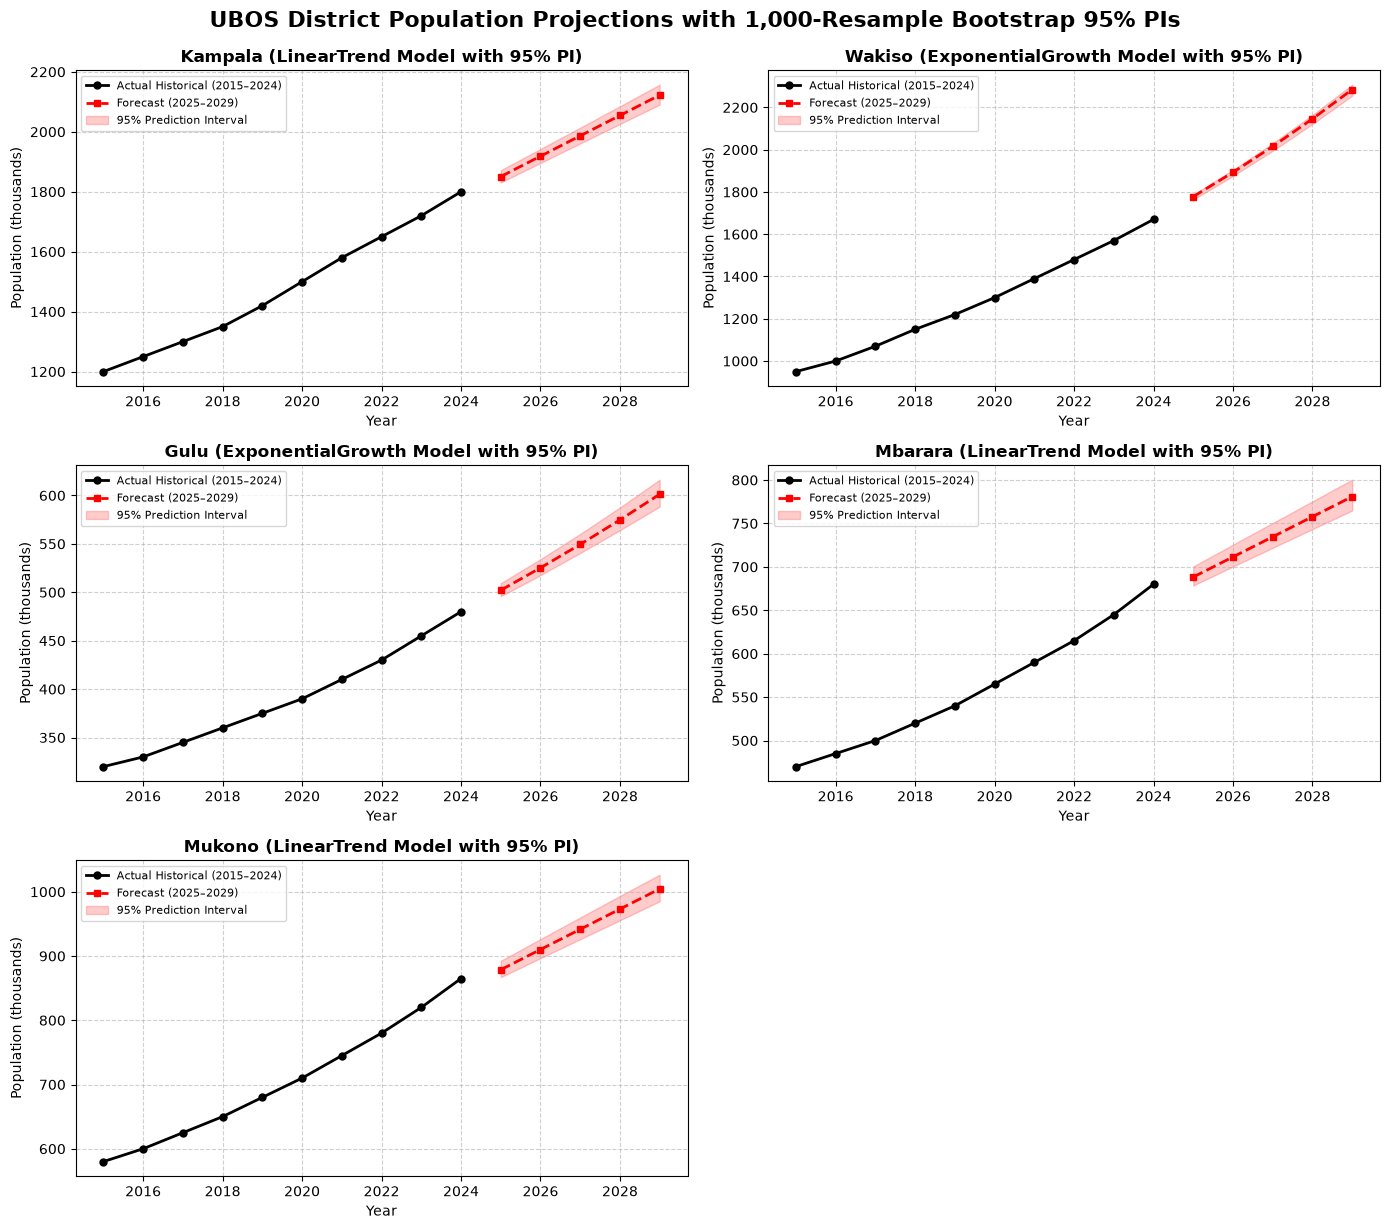

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from project1_population import (
    LinearTrendForecaster,
    ExponentialGrowthForecaster
)

# Dataset, selected models, and random seed for reproducibility
dataset_models = {
    "Kampala": ( [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800], LinearTrendForecaster() ),
    "Wakiso":  ( [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670], ExponentialGrowthForecaster() ),
    "Gulu":    ( [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480], ExponentialGrowthForecaster() ),
    "Mbarara": ( [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680], LinearTrendForecaster() ),
    "Mukono":  ( [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865], LinearTrendForecaster() )
}

years = np.array(list(range(2015, 2025)))
forecast_years = np.arange(2025, 2030)
horizon = 5
n_bootstraps = 1000
np.random.seed(42)

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 12), sharex=False)
axes = axes.flatten()

for idx, (district, (pops, model)) in enumerate(dataset_models.items()):
    ax = axes[idx]
    pops_arr = np.array(pops, dtype=float)
    
    # 1. Fit original model on full historical data and get point forecasts
    model.fit(years, pops_arr)
    point_forecasts = model.predict(horizon=horizon)
    
    # 2. Compute in-sample residuals
    # To get fitted values on training years for residual calculation:
    # We can approximate historical fitted values depending on model type
    if isinstance(model, LinearTrendForecaster):
        t = years - years[0]
        fitted_vals = np.poly1d(model.coeffs)(t)
    elif isinstance(model, ExponentialGrowthForecaster):
        t_exp = np.arange(len(years))
        # Exponential fit curve: P_0 * exp(r * t)
        fitted_vals = pops_arr[0] * np.exp(model.r * t_exp)
    
    residuals = pops_arr - fitted_vals
    # Center residuals to have mean zero
    residuals = residuals - np.mean(residuals)
    
    # 3. Perform Residual Bootstrap Resampling (1,000 resamples)
    boot_forecasts = np.zeros((n_bootstraps, horizon))
    
    for i in range(n_bootstraps):
        # Sample residuals with replacement
        sampled_residuals = np.random.choice(residuals, size=len(pops_arr), replace=True)
        boot_y = fitted_vals + sampled_residuals
        
        # Refit model on bootstrapped series
        boot_model = type(model)()
        boot_model.fit(years, boot_y)
        boot_forecasts[i, :] = boot_model.predict(horizon=horizon)
        
    # 4. Extract 95% Prediction Intervals (2.5th and 97.5th percentiles)
    ci_lower = np.percentile(boot_forecasts, 2.5, axis=0)
    ci_upper = np.percentile(boot_forecasts, 97.5, axis=0)
    
    # 5. Plotting
    ax.plot(years, pops_arr, 'o-', color='black', label='Actual Historical (2015–2024)', linewidth=2, markersize=5)
    ax.plot(forecast_years, point_forecasts, 's--', color='red', label='Forecast (2025–2029)', linewidth=2, markersize=5)
    
    # Shade 95% Prediction Interval
    ax.fill_between(
        forecast_years, ci_lower, ci_upper, 
        color='red', alpha=0.2, label='95% Prediction Interval'
    )
    
    model_name = type(model).__name__.replace("Forecaster", "")
    ax.set_title(f"{district} ({model_name} Model with 95% PI)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Year", fontsize=10)
    ax.set_ylabel("Population (thousands)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left', fontsize=8)

# Remove the unused 6th subplot grid
if len(dataset_models) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.suptitle("UBOS District Population Projections with 1,000-Resample Bootstrap 95% PIs", fontsize=16, fontweight='bold', y=1.02)
plt.show()

In [ ]:
## 5. Critical Assessment of the Fibonacci-Ratio Model
* **Empirical Performance:** Produced high MAPEs (4.8%–6.4%) during backtesting, systematically overshooting demographic shifts.
* **Theoretical Flaw:** Growth relies on rabbit-breeding recurrence sequences rather than socio-economic drivers (fertility, migration, urbanization).
* **Verdict:** Unsuitable for real-world municipal infrastructure planning, though valuable for testing OOP interface polymorphism and error-handling robustness.